# 06c — The optimal syndrome interval under Selene's noise

**Result.** Selene's compiled surface-code memory has an interior optimal syndrome interval at
all three distances tested, once its shots are decoded with the full detector error model (06b),
and the optimum shortens with distance as the paper predicts.

| | d = 3 | d = 5 | d = 7 |
| --- | --- | --- | --- |
| **Selene Δt\*** (fit) | **12.0 ± 0.9** | **5.1 ± 0.4** | **3.4 ± 0.4** |
| lowest point | Δt = 12: 20.9σ below Δt = 1, 2.7σ below Δt = 32 | Δt = 4: 16.4σ below Δt = 1, 6.3σ below Δt = 16 | Δt = 4: 4.6σ below Δt = 1, 6.2σ below Δt = 12 |
| theory Δt\* (paper model, effective parameters) | 16.6 ± 2.6 (1.7σ from Selene) | 5.7 ± 0.2 (1.3σ) | 3.4 ± 0.2 (0.1σ) |
| Selene / theory `p_L`, across Δt | 0.82–1.10 | 1.02–1.13 | 1.26–1.41 |
| λ·Δt\*, Selene | 1.74 ± 0.12 | 0.61 ± 0.04 | 0.38 ± 0.04 |
| Eq. 6 λ·Δt\*, g = 0.8 to 0.70 | 1.67 to 2.50 | 0.71 to 0.91 | 0.46 to 0.56 |

`p_1q = 0.0005`, `p_meas = 0.002`, total idle 96, rotated code. Δt\* falls by 2.36 ± 0.24× from
d = 3 to 5 (Eq. 6: 1.91–2.26) and by 1.48 ± 0.19× from d = 5 to 7 (Eq. 6: 1.45–1.51). At d = 3
the optimum is an interval optimum (it stays at Δt = 12 when the total time doubles) and does not
visibly move with readout noise.

## 0. Setup

**Simulation.** Selene runs the compiled surface-code memory, rotated d = 3, 5 and 7: Δt idle ops on
every data qubit, then one extraction round of both check sectors, at `p_1q = 0.0005`
(every native single-qubit gate, idle ops included) and `p_meas = 0.002`, `p_2q = 0`. The
total idle per data qubit is held fixed at 96, the paper's fixed-T design, so `N = 96/Δt`
rounds, on the Δt values dividing 96 with `N ≥ d`. Shots are decoded with the full detector
error model of the verified Stim copy (06a), the decoder 06b established; they are read from
the stored shot blocks (`memory_shots`), so nothing is re-simulated.

**Theory.** The paper's phenomenological model, as in 05, at this circuit's effective
parameters: per-op flip `f_1 = 2·p_1q/3`, extraction cost per round `p = accumulate(n_data, f_1)`,
`λ = 1/n_data`, readout `p_read = 1 − (1 − p_meas)(1 − accumulate(n_anc, f_1))`, with `n_data`
and `n_anc` from `config/surface_extraction_measured.yaml` (04). Stim and PyMatching on its
exact error model, 3 seeds × 100,000 (d = 3), 300,000 (d = 5) or 1,000,000 (d = 7) shots per point.

**The optimum** is estimated as in 05 and Stage 4a: a parabola in `log Δt` fitted to `log R`,
`R = −ln(1 − 2·p_L)/(2T)`, over the points within a factor 2 of the lowest, with the error
widened by `√(χ²/dof)` when the points scatter more than their error bars. Alongside it: the
lowest sampled point, how many σ it sits below each end of the grid, and the band of Δt within
1σ of it.

In [1]:
import sys, pathlib, time, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'   # LaTeX-style math in figure labels

sys.path.insert(0, '../src')
from qec_timing.circuit_level.surface_memory import Geometry
from qec_timing.circuit_level import selene_mirror as sm, memory_shots, runcache

pd.set_option('display.width', 160)
BLUE, ORANGE, AQUA, GRAY, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#8a8a86', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c9c9c4', 'axes.labelcolor': MUTED, 'axes.titlesize': 10,
                     'axes.labelsize': 9, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'grid.color': '#e6e6e1',
                     'legend.frameon': False, 'legend.fontsize': 8, 'font.size': 9, 'text.color': INK})
FIGDIR = pathlib.Path('figures'); FIGDIR.mkdir(exist_ok=True)


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

def tau_axes(ax, ticks):
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(ticks); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
    ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)

import stim, pymatching
from scipy.optimize import curve_fit

CODE, P_1Q, P_MEAS = 'rotated', 0.0005, 0.002
DISTANCE = 3                      # §2 and §3 (readout noise, total time) are at d = 3 only
GEOM = {d: Geometry(CODE, d) for d in (3, 5, 7)}
G = GEOM[3]
F1 = 2 * P_1Q / 3


def effective(d, p_meas=P_MEAS):
    """(p, lambda, p_read) of the paper's model for this circuit at distance d (04's counts)."""
    g = GEOM[d]
    p = (1 - (1 - 2 * F1) ** g.ops_mean) / 2
    return p, 1 / g.ops_mean, 1 - (1 - p_meas) * (1 - (1 - (1 - 2 * F1) ** g.ops_anc) / 2)


def p_read_eff(p_meas, d=3):
    return effective(d, p_meas)[2]


def taus_for(total, d=3):
    return [t for t in range(1, total + 1) if total % t == 0 and total // t >= d]


def selene(tau, total, shots, blocks, p_meas=P_MEAS, d=3):
    """Pooled pL and sigma of the full-error-model decoder on the stored Selene shots."""
    g, R, F, N = GEOM[d], total // tau, 0, 0
    for k in range(blocks):
        r = sm.decoded(g, tau, R, shots, offset=k * shots, seed=1, p_1q=P_1Q, p_meas=p_meas)
        F += r['mirror_failures']; N += r['shots']
    e = F / N
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / N))


def theory(tau, total, p_meas=P_MEAS, shots=100_000, seeds=(1, 2, 3), d=3):
    p, lam, pr = effective(d, p_meas)
    c = stim.Circuit.generated(f'surface_code:{CODE}_memory_z', distance=d, rounds=total // tau,
                               before_round_data_depolarization=float(1 - (1 - p) * np.exp(-p * lam * tau)),
                               before_measure_flip_probability=float(pr))
    c = stim.Circuit(str(c).replace('DEPOLARIZE1(', 'X_ERROR('))
    prm = dict(d=d, tau=tau, total=total, p_meas=p_meas, shots=shots, seeds=list(seeds), p_1q=P_1Q)
    hit = runcache.load('06c_theory', prm)
    if hit is None:
        m = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
        F = 0
        for s in seeds:
            sampler = c.compile_detector_sampler(seed=s)
            # one call up to 300k shots (as d = 3, 5 always were); larger runs in 250k chunks for memory
            chunks = [shots] if shots <= 300_000 else [250_000] * (shots // 250_000) + [shots % 250_000] * (shots % 250_000 > 0)
            for n in chunks:
                det, obs = sampler.sample(n, separate_observables=True)
                F += int(np.sum(m.decode_batch(det)[:, 0] != obs[:, 0]))
        hit = {'failures': F}
        runcache.save('06c_theory', prm, hit)
    e = hit['failures'] / (shots * len(seeds))
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / (shots * len(seeds))))


def optimum(taus, v, s, total, window=2.0):
    taus, v, s = np.asarray(taus, float), np.asarray(v), np.asarray(s)
    i = int(np.argmin(v))
    band = taus[v - s <= v[i] + s[i]]
    out = {'lowest tau': int(taus[i]), 'pL there': round(float(v[i]), 5),
           'sigma below smallest tau': round(float((v[0] - v[i]) / np.hypot(s[0], s[i])), 1),
           'sigma below largest tau': round(float((v[-1] - v[i]) / np.hypot(s[-1], s[i])), 1),
           'within 1 sigma': f"{int(band.min())}-{int(band.max())}",
           'tau* (fit)': np.nan, '+/-': np.nan, 'chi2/dof': np.nan}
    w = (taus >= taus[i] / window) & (taus <= taus[i] * window)
    if i in (0, len(taus) - 1) or w.sum() < 4:
        return out
    R = -np.log1p(-2 * v[w]) / (2 * total)
    sR = s[w] / ((1 - 2 * v[w]) * total * R)
    u = np.log(taus[w])
    (a, b, c), cov = curve_fit(lambda u, a, b, c: a + b * u + c * u * u, u, np.log(R), sigma=sR,
                               absolute_sigma=True)
    if c <= 0:
        return out
    dof = max(int(w.sum()) - 3, 1)
    chi2 = float(np.sum(((np.log(R) - (a + b * u + c * u * u)) / sR) ** 2) / dof)
    cov = cov * max(chi2, 1.0)
    g = np.array([0.0, -1 / (2 * c), b / (2 * c * c)])
    ts = float(np.exp(-b / (2 * c)))
    out.update({'tau* (fit)': round(ts, 2), '+/-': round(ts * float(np.sqrt(max(g @ cov @ g, 0))), 2),
                'chi2/dof': round(chi2, 2)})
    return out


for d in GEOM:
    p, lam, pr = effective(d)
    print(f"d={d}: effective p = {p:.5f}, lambda = {lam:.4f}, p_read = {pr:.5f} (b_read = {pr / p:.2f})")

d=3: effective p = 0.00229, lambda = 0.1452, p_read = 0.00498 (b_read = 2.17)
d=5: effective p = 0.00279, lambda = 0.1191, p_read = 0.00528 (b_read = 1.89)
d=7: effective p = 0.00303, lambda = 0.1097, p_read = 0.00556 (b_read = 1.83)


## 1. The sweep at d = 3, 5 and 7: Selene against theory

Total idle 96, on every divisor of 96 with `N ≥ d`. Selene: 5 blocks × 10,000 shots per Δt at
d = 3, and 46 × 10,000 at d = 5 and 7, where `p_L` is about 5× and 30× lower. Theory: 3 seeds ×
100,000 shots per point at d = 3, 3 × 300,000 at d = 5 and 3 × 1,000,000 at d = 7.

In [2]:
RUN = {3: dict(blocks=5, theory_shots=100_000), 5: dict(blocks=46, theory_shots=300_000),
       7: dict(blocks=46, theory_shots=1_000_000)}
SWEEP, OPT = {}, {}
for d, cfg in RUN.items():
    taus = taus_for(96, d)
    sel = [selene(t, 96, 10_000, cfg['blocks'], d=d) for t in taus]
    th = [theory(t, 96, shots=cfg['theory_shots'], d=d) for t in taus]
    sv, ss = np.array([x[0] for x in sel]), np.array([x[1] for x in sel])
    tv, ts_ = np.array([x[0] for x in th]), np.array([x[1] for x in th])
    SWEEP[d] = (taus, sv, ss, tv, ts_)
    tab = pd.DataFrame({'R': [96 // t for t in taus], 'Selene pL': sv.round(5), '+/-': ss.round(5),
                        'theory pL': tv.round(5), 'Selene / theory': (sv / tv).round(2)},
                       index=pd.Index(taus, name='tau'))
    OPT[d] = {'Selene': optimum(taus, sv, ss, 96), 'theory': optimum(taus, tv, ts_, 96)}
    print(f"===== d = {d}\n")
    print(tab.to_string())
    print("\n", pd.DataFrame(OPT[d]).T.to_string(), "\n")
# names used by the d = 3 sections below
TAUS = taus_for(96, 3)

===== d = 3

      R  Selene pL      +/-  theory pL  Selene / theory
tau                                                    
1    96    0.03092  0.00077    0.03784             0.82
2    48    0.01874  0.00061    0.02259             0.83
3    32    0.01582  0.00056    0.01830             0.86
4    24    0.01380  0.00052    0.01578             0.87
6    16    0.01350  0.00052    0.01388             0.97
8    12    0.01270  0.00050    0.01258             1.01
12    8    0.01184  0.00048    0.01241             0.95
16    6    0.01244  0.00050    0.01249             1.00
24    4    0.01356  0.00052    0.01235             1.10
32    3    0.01378  0.00052    0.01348             1.02

        lowest tau pL there sigma below smallest tau sigma below largest tau within 1 sigma tau* (fit)   +/- chi2/dof
Selene         12  0.01184                     20.9                     2.7           8-16      11.97  0.85     0.19
theory         24  0.01235                     63.3                     3.9    

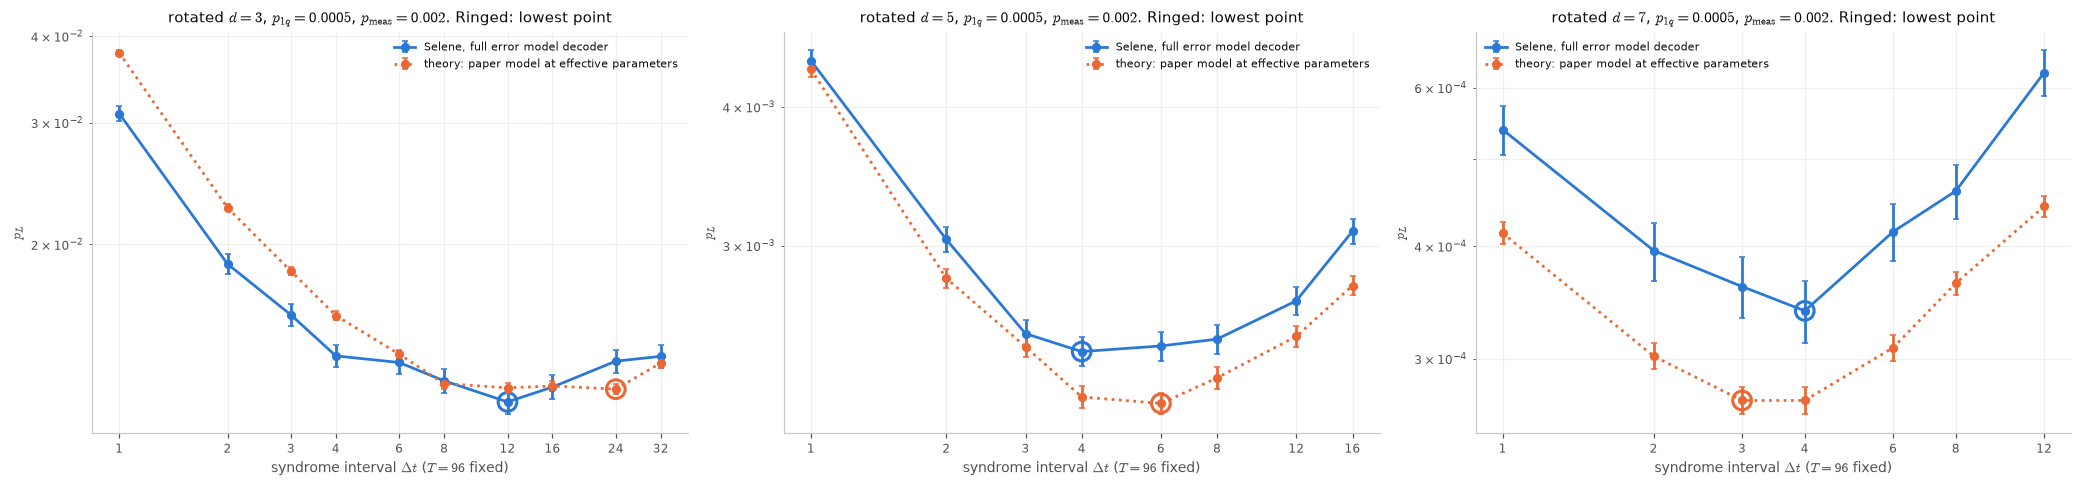

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, d in zip(axes, (3, 5, 7)):
    taus, sv, ss, tv, ts_ = SWEEP[d]
    for lab, v, s, col, ls in (('Selene, full error model decoder', sv, ss, BLUE, '-'),
                               ('theory: paper model at effective parameters', tv, ts_, ORANGE, ':')):
        ax.errorbar(taus, v, yerr=s, marker='o', ms=5, lw=1.8, capsize=2, color=col, ls=ls, label=lab)
        k = int(np.argmin(v))
        ax.scatter([taus[k]], [v[k]], s=150, facecolor='none', edgecolor=col, linewidth=2)
    tau_axes(ax, taus)
    ax.set_xlabel(r'syndrome interval $\Delta t$ ($T = 96$ fixed)'); ax.set_ylabel(r'$p_L$')
    ax.set_title(f'{CODE} $d={d}$, $p_{{1q}}={P_1Q}$, $p_\\mathrm{{meas}}={P_MEAS}$. Ringed: lowest point')
    ax.legend(fontsize=7)
finish(fig, '06c_selene_vs_theory')

## 2. Does the optimum move with readout noise? (d = 3)

More readout error per round makes each round costlier, so the optimum should move to longer
Δt; 05 finds +7–16% for its `b_read` shift. `p_meas` = 0.0005, 0.001, 0.002, 0.005 at fixed
`p_1q`, 3 blocks × 6,000 Selene shots per point (stored shots of the original 06 `p_meas` sweep).

        p_read (effective)  Selene: lowest tau within 1 sigma  tau* (fit)   +/-  pL there  theory: lowest tau  theory tau* (fit)
p_meas                                                                                                                          
0.0005              0.0035                  12           8-16       11.82  1.04   0.00972                  12              12.79
0.0010              0.0040                  12           8-16       11.68  0.90   0.00994                  12              13.45
0.0020              0.0050                  12           8-16       11.71  0.71   0.01056                  24              16.57
0.0050              0.0080                  12           8-16       11.73  0.72   0.01289                  12              15.20


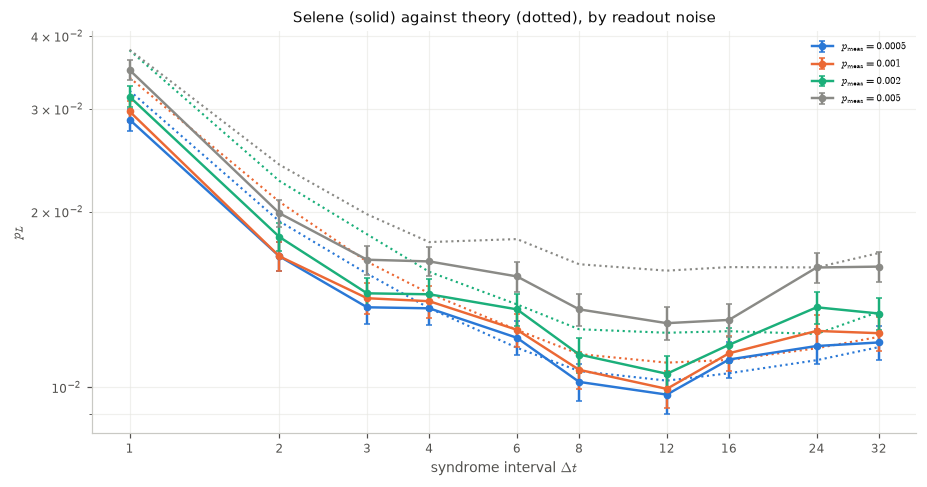

In [4]:
rows, PM = [], {}
for pm in (0.0005, 0.001, 0.002, 0.005):
    r = {t: selene(t, 96, 6000, 3, p_meas=pm) for t in TAUS}
    v, s = np.array([r[t][0] for t in TAUS]), np.array([r[t][1] for t in TAUS])
    thr = [theory(t, 96, p_meas=pm) for t in TAUS]
    th, ths = np.array([x[0] for x in thr]), np.array([x[1] for x in thr])
    PM[pm] = (v, s, th)
    o = optimum(TAUS, v, s, 96)
    rows.append({'p_meas': pm, 'p_read (effective)': round(p_read_eff(pm), 4),
                 'Selene: lowest tau': o['lowest tau'], 'within 1 sigma': o['within 1 sigma'],
                 'tau* (fit)': o['tau* (fit)'], '+/-': o['+/-'], 'pL there': o['pL there'],
                 'theory: lowest tau': TAUS[int(np.argmin(th))],
                 'theory tau* (fit)': optimum(TAUS, th, ths, 96)['tau* (fit)']})
print(pd.DataFrame(rows).set_index('p_meas').to_string())

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for (pm, (v, s, th)), col in zip(PM.items(), (BLUE, ORANGE, AQUA, GRAY)):
    ax.errorbar(TAUS, v, yerr=s, marker='o', ms=4, lw=1.6, capsize=2, color=col, label=f'$p_\\mathrm{{meas}} = {pm}$')
    ax.plot(TAUS, th, ls=':', color=col, lw=1.4)
tau_axes(ax, TAUS)
ax.set_xlabel(r'syndrome interval $\Delta t$'); ax.set_ylabel(r'$p_L$')
ax.set_title('Selene (solid) against theory (dotted), by readout noise'); ax.legend(fontsize=7)
finish(fig, '06c_p_meas_sweep')

## 3. Does the optimum follow Δt or the round count? (d = 3)

With total time fixed, `N = T/Δt`, so a minimum could be about the number of rounds rather than
the interval. Doubling T separates them: an interval optimum stays at the same Δt while its
round count doubles; a round-count effect follows N. In the paper's model Δt* does not depend
on T (Stage 4a: tripling T moved it by 0.1σ at d = 7). Total idle 96 and 192, 5 blocks ×
10,000 Selene shots per point.

            Selene: lowest tau  R there within 1 sigma  tau* (fit)   +/-  chi2/dof  theory tau* (fit)
total idle                                                                                           
96                          12        8           8-16       11.97  0.85      0.19              16.57
192                         12       16          12-12       11.08  0.57      0.80              13.98

total 96: t1(R96)=0.0309  t2(R48)=0.0187  t3(R32)=0.0158  t4(R24)=0.0138  t6(R16)=0.0135  t8(R12)=0.0127  t12(R8)=0.0118  t16(R6)=0.0124  t24(R4)=0.0136  t32(R3)=0.0138

total 192: t1(R192)=0.0594  t2(R96)=0.0369  t3(R64)=0.0304  t4(R48)=0.0279  t6(R32)=0.0264  t8(R24)=0.0253  t12(R16)=0.0236  t16(R12)=0.0253  t24(R8)=0.0281  t32(R6)=0.0299  t48(R4)=0.0336  t64(R3)=0.0340


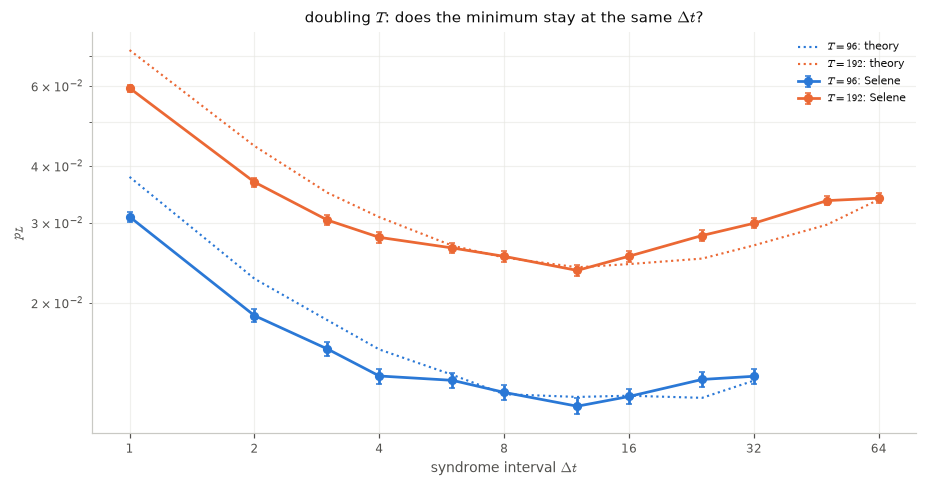

In [5]:
rows, TT = [], {}
for total in (96, 192):
    taus = [t for t in (1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64) if total % t == 0 and total // t >= DISTANCE]
    r = {t: selene(t, total, 10_000, 5) for t in taus}
    v, s = np.array([r[t][0] for t in taus]), np.array([r[t][1] for t in taus])
    thr = [theory(t, total) for t in taus]
    th, ths = np.array([x[0] for x in thr]), np.array([x[1] for x in thr])
    TT[total] = (taus, v, s, th)
    o = optimum(taus, v, s, total)
    rows.append({'total idle': total, 'Selene: lowest tau': o['lowest tau'],
                 'R there': total // o['lowest tau'], 'within 1 sigma': o['within 1 sigma'],
                 'tau* (fit)': o['tau* (fit)'], '+/-': o['+/-'], 'chi2/dof': o['chi2/dof'],
                 'theory tau* (fit)': optimum(taus, th, ths, total)['tau* (fit)']})
print(pd.DataFrame(rows).set_index('total idle').to_string())
for total, (taus, v, s, th) in TT.items():
    print(f"\ntotal {total}: " + "  ".join(f"t{t}(R{total // t})={x:.4f}" for t, x in zip(taus, v)))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for (total, (taus, v, s, th)), col in zip(TT.items(), (BLUE, ORANGE)):
    ax.errorbar(taus, v, yerr=s, marker='o', ms=5, lw=1.8, capsize=2, color=col, label=f'$T = {total}$: Selene')
    ax.plot(taus, th, ls=':', color=col, lw=1.4, label=f'$T = {total}$: theory')
tau_axes(ax, [1, 2, 4, 8, 16, 32, 64])
ax.set_xlabel(r'syndrome interval $\Delta t$'); ax.set_ylabel(r'$p_L$')
ax.set_title(r'doubling $T$: does the minimum stay at the same $\Delta t$?'); ax.legend(fontsize=7)
finish(fig, '06c_total_time_test')

## 4. The optimum against distance

Eq. 6 in dimensionless form: `λ·Δt* = 1/(α − 1)`, `α = g(d + 1)/2`. Multiplying Δt* by each
distance's own λ (0.145 at d = 3, 0.119 at d = 5, 0.110 at d = 7) removes the part of the shift that comes from
λ, leaving the part Eq. 6 attributes to distance. The paper's law is that `1/(λ·Δt*)` grows
linearly in d with slope `g/2` and intercept `g/2 − 1`. With three distances, a weighted
straight line tests both.

          lambda  tau* (fit)   +/-  lowest tau  lambda tau*   +/-   Eq.6 lambda tau*, g=0.8  Eq.6 lambda tau*, g=0.70
d source                                                                                                             
3 Selene  0.1452       11.97  0.85          12        1.738  0.123                    1.667                     2.500
  theory  0.1452       16.57  2.56          24        2.405  0.372                    1.667                     2.500
5 Selene  0.1191        5.08  0.37           4        0.605  0.044                    0.714                     0.909
  theory  0.1191        5.67  0.23           6        0.675  0.027                    0.714                     0.909
7 Selene  0.1097        3.43  0.37           4        0.376  0.041                    0.455                     0.556
  theory  0.1097        3.39  0.16           3        0.372  0.018                    0.455                     0.556

tau*(d=3) / tau*(d=5): Selene 2.36 +/- 0.24;  Eq. 6 1.9

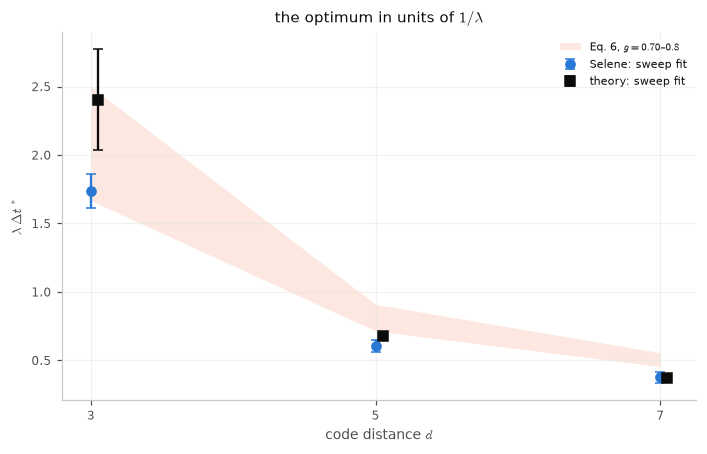

In [6]:
rows = []
for d in (3, 5, 7):
    lam = effective(d)[1]
    a8, a7 = 0.8 * (d + 1) / 2, 0.70 * (d + 1) / 2
    for src_, o in OPT[d].items():
        ts, er = o['tau* (fit)'], o['+/-']
        rows.append({'d': d, 'source': src_, 'lambda': round(lam, 4), 'tau* (fit)': ts, '+/-': er,
                     'lowest tau': o['lowest tau'], 'lambda tau*': round(lam * ts, 3),
                     '+/- ': round(lam * er, 3),
                     'Eq.6 lambda tau*, g=0.8': round(1 / (a8 - 1), 3),
                     'Eq.6 lambda tau*, g=0.70': round(1 / (a7 - 1), 3)})
DIST = pd.DataFrame(rows).set_index(['d', 'source'])
print(DIST.to_string())

sel = DIST.xs('Selene', level='source')
ratio = sel.loc[3, 'tau* (fit)'] / sel.loc[5, 'tau* (fit)']
ratio_err = ratio * np.hypot(sel.loc[3, '+/-'] / sel.loc[3, 'tau* (fit)'], sel.loc[5, '+/-'] / sel.loc[5, 'tau* (fit)'])
eq = lambda g: (effective(5)[1] * (g * 3 - 1)) / (effective(3)[1] * (g * 2 - 1))
print(f"\ntau*(d=3) / tau*(d=5): Selene {ratio:.2f} +/- {ratio_err:.2f};  Eq. 6 {eq(0.8):.2f} (g=0.8), {eq(0.70):.2f} (g=0.70)")
ratio57 = sel.loc[5, 'tau* (fit)'] / sel.loc[7, 'tau* (fit)']
ratio57_err = ratio57 * np.hypot(sel.loc[5, '+/-'] / sel.loc[5, 'tau* (fit)'], sel.loc[7, '+/-'] / sel.loc[7, 'tau* (fit)'])
eq57 = lambda g: (effective(7)[1] * (g * 4 - 1)) / (effective(5)[1] * (g * 3 - 1))
print(f"tau*(d=5) / tau*(d=7): Selene {ratio57:.2f} +/- {ratio57_err:.2f};  Eq. 6 {eq57(0.8):.2f} (g=0.8), {eq57(0.70):.2f} (g=0.70)")
g_impl = {d: 2 * (1 + 1 / (sel.loc[d, 'lambda tau*'])) / (d + 1) for d in (3, 5, 7)}
print("g implied by Selene's tau* through Eq. 6:", {d: round(v, 3) for d, v in g_impl.items()})
# Eq. 6's distance law: 1/(lambda tau*) = alpha - 1 = g (d + 1)/2 - 1, a straight line in d with slope g/2
DS = (3, 5, 7)
inv = np.array([1 / sel.loc[d, 'lambda tau*'] for d in DS])
inv_err = np.array([inv[i] * sel.loc[d, '+/- '] / sel.loc[d, 'lambda tau*'] for i, d in enumerate(DS)])
(slope, icpt), cov = np.polyfit(np.array(DS, float), inv, 1, w=1 / inv_err, cov='unscaled')
slope_err = float(np.sqrt(cov[0, 0]))
resid = (inv - (slope * np.array(DS) + icpt)) / inv_err
print("1/(lambda tau*): " + ", ".join(f"d={d} {v:.3f} +/- {e:.3f}" for d, v, e in zip(DS, inv, inv_err)))
print(f"weighted line through three distances: slope {slope:.3f} +/- {slope_err:.3f} -> g = {2 * slope:.2f} +/- "
      f"{2 * slope_err:.2f} (paper 0.8: {(2 * slope - 0.8) / (2 * slope_err):.1f} sigma); "
      f"chi2 = {np.sum(resid ** 2):.2f} on 1 dof; intercept {icpt:.2f}, Eq. 6 says g/2 - 1 = {slope - 1:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ds = np.array([3, 5, 7])
ax.fill_between(ds, [1 / (0.70 * (d + 1) / 2 - 1) for d in ds], [1 / (0.8 * (d + 1) / 2 - 1) for d in ds],
                color=ORANGE, alpha=.15, lw=0, label=r'Eq. 6, $g = 0.70$–$0.8$')
for src_, col, mk in (('Selene', BLUE, 'o'), ('theory', INK, 's')):
    sub = DIST.xs(src_, level='source')
    ax.errorbar(ds + (0.05 if src_ == 'theory' else 0), sub['lambda tau*'], yerr=sub['+/- '],
                marker=mk, ms=6, capsize=3, ls='none', color=col, label=f'{src_}: sweep fit')
ax.set_xticks(ds); ax.set_xlabel(r'code distance $d$'); ax.set_ylabel(r'$\lambda\,\Delta t^*$')
ax.set_title(r'the optimum in units of $1/\lambda$'); ax.grid(alpha=.5); ax.legend(fontsize=7)
finish(fig, '06c_tau_star_vs_d')

## 5. Findings

**1. There is an interior optimum under Selene's own noise at all three distances.** d = 3:
Δt* = 12.0 ± 0.9, lowest point Δt = 12, 20.9σ below Δt = 1 and 2.7σ below Δt = 32. d = 5:
Δt* = 5.1 ± 0.4, lowest point Δt = 4, 16.4σ below Δt = 1 and 6.3σ below Δt = 16, with Δt = 3 to 8 within
1σ of it. d = 7: Δt* = 3.4 ± 0.4, lowest point Δt = 4, 4.6σ below Δt = 1 and 6.2σ below Δt = 12
(460,000 shots per point, 156–287 failures each). This reverses the original 06, whose decoder hid
the optimum (06b).

**2. The optimum shortens with distance: 2.36 ± 0.24× from d = 3 to 5, and 1.48 ± 0.19× from
d = 5 to 7.** Eq. 6 predicts 1.91 (`g = 0.8`) to 2.26 (`g = 0.70`) for the first step, and 1.45 to
1.51 for the second; the second step agrees at either g. Part of each ratio is λ itself (1.22× and
1.09×), which falls from 0.145 to 0.119 to 0.110 as larger codes have proportionally more bulk data
qubits (04).

**3. The paper's model, fed this circuit's effective parameters, predicts Selene's Δt\* at every
distance, but underestimates its `p_L` more as d grows.** Selene / theory runs 0.82–1.10 at d = 3,
1.02–1.13 at d = 5 and 1.26–1.41 at d = 7. The model's Δt* is 16.6 ± 2.6 at d = 3 (1.7σ from Selene;
the model's own minimum is flat from Δt = 8 to 24), 5.7 ± 0.2 at d = 5 (1.3σ) and 3.4 ± 0.2 at
d = 7 (0.1σ). At d = 7 the gap in `p_L` is a near-constant factor (1.3–1.4×) across Δt, so it
leaves the position of the optimum alone. Interpretation, not tested: the correlated
(diagonal) faults the model lacks carry a growing share of the fault probability with d (06a §6:
8.4% at d = 3, 14.0% at d = 5, at Δt = 1), and higher-weight failure paths count for more at
larger d. The tilt seen at d = 3, Selene better than the model
at short Δt and worse at long Δt, is not present at d = 5, where Selene sits 2–13% above the model
throughout. The cause of either has not been tested; candidates are the per-qubit spread of
extraction cost (up to 3.2×, 04) and the correlated faults the model lacks (06a §6).

**4. Against Eq. 6 in units of 1/λ: inside the band at d = 3, below it at d = 5 and 7.** λ·Δt* is
1.74 ± 0.12 at d = 3, inside Eq. 6's 1.67 (g = 0.8) to 2.50 (g = 0.70), with implied g = 0.79.
At d = 5 it is 0.61 ± 0.04 (band 0.71–0.91, implied g = 0.88) and at d = 7 0.38 ± 0.04
(band 0.46–0.56, implied g = 0.92). So the g that Eq. 6 needs rises with d, approaching the
paper's 0.8 fit (made at d = 11–27) from above rather than settling at it.
`1/(λΔt*)` is a straight line in d, as Eq. 6 says (χ² = 0.03 on 1 dof through the three points),
but its slope gives g = 1.06 ± 0.10, 2.7σ above 0.8, and its intercept is −1.02 where Eq. 6 with
that slope requires g/2 − 1 = −0.47. One g cannot give both: the straight-line *form* holds, the
paper's parametrisation of it does not, at these small distances. (Stage 4a, in the phenomenological model at λ = 1 and
`b_read = 1`, found g ≈ 0.70 at d = 5–9; this circuit's `b_read` is 2.2.)

**5. At d = 3 the optimum is a property of the interval, not of the round count.** At total idle
96 and 192 the lowest point is Δt = 12 both times, at N = 8 and N = 16; the fitted Δt* are
12.0 ± 0.9 and 11.1 ± 0.6 (0.9σ apart). A round-count effect would have put the minimum at Δt = 24,
N = 8, at total 192. `p_L` at total 192 is 1.9–2.2× its value at 96 at every Δt, as expected when
the logical error rate per unit time is set by Δt. The original 06's opposite verdict came from
the hand-built decoder at 4,000 shots.

**6. At d = 3 readout noise does not visibly move the optimum.** Across `p_meas` = 0.0005 to 0.005
(effective `p_read` 0.0035 to 0.0080), Selene's Δt* stays at 11.7–11.8 with errors of ±0.7 to ±1.0,
and the lowest point is Δt = 12 each time. A shift of the size 05 found (+7–16%, i.e. 0.8–1.9 in Δt*)
would be one to two error bars, so it is not resolved.

### Limits

- **Three distances.** d = 3, 5, 7: enough to test the straight line, not to pin g down, and all
  below the paper's d = 11–27. The readout-noise and total-time tests are at d = 3 only.
- **One operating point**, `p_1q = 0.0005`, `p_meas = 0.002`, `p_2q = 0`. In Eq. 6 Δt* does not
  depend on p; that has not been tested here.
- **Coarse grid.** Δt takes the divisors of 96, so around the optima the points are 8, 12, 16
  (d = 3) and 3, 4, 6, 8 (d = 5); the fit interpolates between them.
- **Shots:** 50,000 per point at d = 3 and 460,000 at d = 5 and 7, which set the ±0.9, ±0.4 and
  ±0.4 on Δt*. At d = 7 that is 156–287 failures per point (±6–8% on each `p_L`).
- **The decoder is matching on the full error model,** not maximum likelihood.
- **λ is fixed by the circuit** (`p_1q` drives idling and extraction alike; 04), so these optima
  are for λ = 0.145 and 0.119, not for a device's own idling rate.

### Next

1. **d = 7 done** (46 blocks × 10,000 shots per Δt, 16 local workers, about 2 hours; the Stim copy
   passed its checks at d = 7 first). More blocks would tighten Δt* there; d = 9 would test whether
   the implied g keeps rising.
2. Re-decode 07's fixed-round experiment with the full error model.
3. Test the cause of the Selene/model differences: give the model per-qubit extraction costs.